# 09 — Per-Gameweek Point Buckets (last season, 2025/26)

A season total hides *shape*. Two 150-point midfielders can get there via steady 5s or via
a fistful of hauls between blanks. We bucket **every player-GW** of last season into four
tiers and count how a player's season splits across them.

- **Data:** vaastav `2025-26/gws/merged_gw.csv` only — one row per player per gameweek.
- **Buckets** (on `total_points` per GW): **blank** ≤2 · **pre-return** 3–4 · **return** 5–9
  · **double digit** ≥10. Thresholds are tunable in the Config cell.
- **CS framing:** discretise a continuous scalar (`total_points`) into ordered bins, then
  count-aggregate per player — a histogram per player, rendered as a stacked share bar.

In [90]:
SEASON = "2025-26"          # last completed season
BASE   = f"https://raw.githubusercontent.com/vaastav/Fantasy-Premier-League/master/data/{SEASON}"
MERGED_URL = f"{BASE}/gws/merged_gw.csv"

# Bucket edges on per-GW total_points. Each bucket is [lo, hi] inclusive.
#   blank        <= 2
#   pre-return   3..4   (played, no full return)
#   return       5..9   (a goal/assist/CS-shaped haul)
#   double digit >= 10
BUCKETS = [
    ("blank",        -10**9, 2),
    ("pre-return",   3,      4),
    ("return",       5,      9),
    ("double digit", 10,     10**9),
]

# Only bucket GWs where the player was actually involved (avoids counting benched 0s as blanks).
COUNT_NONPLAYING = False     # if True, minutes==0 rows also get bucketed (as blanks)

# Analysis universe: top-K per position by TOTAL season points (same shape as #07).
TOP_PER_POS = {"GK": 6, "DEF": 15, "MID": 15, "FWD": 9}

In [91]:
import io, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def read_csv(url):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    return pd.read_csv(io.BytesIO(urllib.request.urlopen(req, timeout=60).read()))

gw = read_csv(MERGED_URL)
print(f"{len(gw):,} player-GW rows | {gw['name'].nunique()} players | "
      f"GWs {gw['round'].min()}-{gw['round'].max()}")

29,757 player-GW rows | 841 players | GWs 1-38


## Assign each player-GW to a bucket
One pass over the raw rows: label every GW with its tier. We optionally drop `minutes == 0`
rows so a season's "blank" count means *played and blanked*, not *didn't play*.

In [92]:
BUCKET_NAMES = [b[0] for b in BUCKETS]

def to_bucket(pts):
    for name, lo, hi in BUCKETS:
        if lo <= pts <= hi:
            return name
    return None

rows = gw if COUNT_NONPLAYING else gw[gw["minutes"] > 0].copy()
rows["bucket"] = rows["total_points"].map(to_bucket)
assert rows["bucket"].notna().all(), "a GW fell outside every bucket - check the edges"

# sanity: every bucket is a contiguous, non-overlapping slice of the points axis
print("bucket distribution across ALL counted player-GWs:")
print(rows["bucket"].value_counts().reindex(BUCKET_NAMES))

bucket distribution across ALL counted player-GWs:
bucket
blank           7269
pre-return      1699
return          2017
double digit     513
Name: count, dtype: int64


## Per-player season shape
For each player: how many of their GWs land in each bucket, plus season totals.

In [93]:
counts = (rows.groupby(["name", "bucket"]).size()
          .unstack("bucket").reindex(columns=BUCKET_NAMES).fillna(0).astype(int))
counts["played"] = counts[BUCKET_NAMES].sum(axis=1)

meta = gw.groupby("name").agg(
    position=("position", "first"),
    team=("team", lambda s: s.mode().iloc[0]),
    total_points=("total_points", "sum"),
).reset_index()

season = meta.merge(counts.reset_index(), on="name")
season = season[season["total_points"] > 0]
print(f"{len(season)} players with a positive season total")

536 players with a positive season total


In [94]:
# Top-K per position by total points -> analysis universe
picks = []
for p, k in TOP_PER_POS.items():
    picks.append(season[season["position"] == p]
                 .sort_values("total_points", ascending=False).head(k))
order = {"GK": 0, "DEF": 1, "MID": 2, "FWD": 3}
uni = (pd.concat(picks, ignore_index=True)
       .sort_values(["position", "total_points"],
                    key=lambda s: s.map(order) if s.name == "position" else s,
                    ascending=[True, False]).reset_index(drop=True))
print(f"{len(uni)} players:", ", ".join(f"{p}x{TOP_PER_POS[p]}" for p in order))

45 players: GKx6, DEFx15, MIDx15, FWDx9


## The table — counts and shares
GW counts per bucket, plus each bucket as a share of games played. `%ret+` (return +
double-digit share) is the headline "how often did this asset actually return" number.

In [95]:
tab = uni[["name", "position", "team", "total_points", "played"] + BUCKET_NAMES].copy()
for b in BUCKET_NAMES:
    tab[f"%{b}"] = (uni[b] / uni["played"] * 100).round(1)
tab["%ret+"] = (tab["%return"] + tab["%double digit"]).round(1)

pretty = tab.rename(columns={"total_points": "pts", "double digit": "DD",
                             "%double digit": "%DD", "%pre-return": "%pre"})
pretty

,name,position,team,pts,played,blank,pre-return,return,DD,%blank,%pre,%return,%DD,%ret+
0,David Raya Martín,GK,Arsenal,162,37,15,3,17,2,40.5,8.1,45.9,5.4,51.3
1,Caoimhín Kelleher,GK,Brentford,143,37,21,4,9,3,56.8,10.8,24.3,8.1,32.4
2,Robin Roefs,GK,Sunderland,136,35,17,7,8,3,48.6,20.0,22.9,8.6,31.5
3,Jordan Pickford,GK,Everton,135,38,23,4,7,4,60.5,10.5,18.4,10.5,28.9
4,Gianluigi Donnarumma,GK,Man City,135,34,16,1,17,0,47.1,2.9,50.0,0.0,50.0
5,Dean Henderson,GK,Crystal Palace,131,37,20,6,10,1,54.1,16.2,27.0,2.7,29.7
6,Gabriel dos Santos Magalhães,DEF,Arsenal,209,32,8,3,15,6,25.0,9.4,46.9,18.8,65.7
7,Marc Guéhi,DEF,Crystal Palace,179,35,12,6,13,4,34.3,17.1,37.1,11.4,48.5
8,Marcos Senesi Barón,DEF,Bournemouth,175,37,13,11,9,4,35.1,29.7,24.3,10.8,35.1
9,Virgil van Dijk,DEF,Liverpool,175,38,14,10,11,3,36.8,26.3,28.9,7.9,36.8


## Money shot — 100% stacked bars, one row per player
Left-to-right reads as **blank → pre-return → return → double-digit**. A long red-orange left
tail is a boom-or-bust asset; a bar weighted right is a reliable returner.

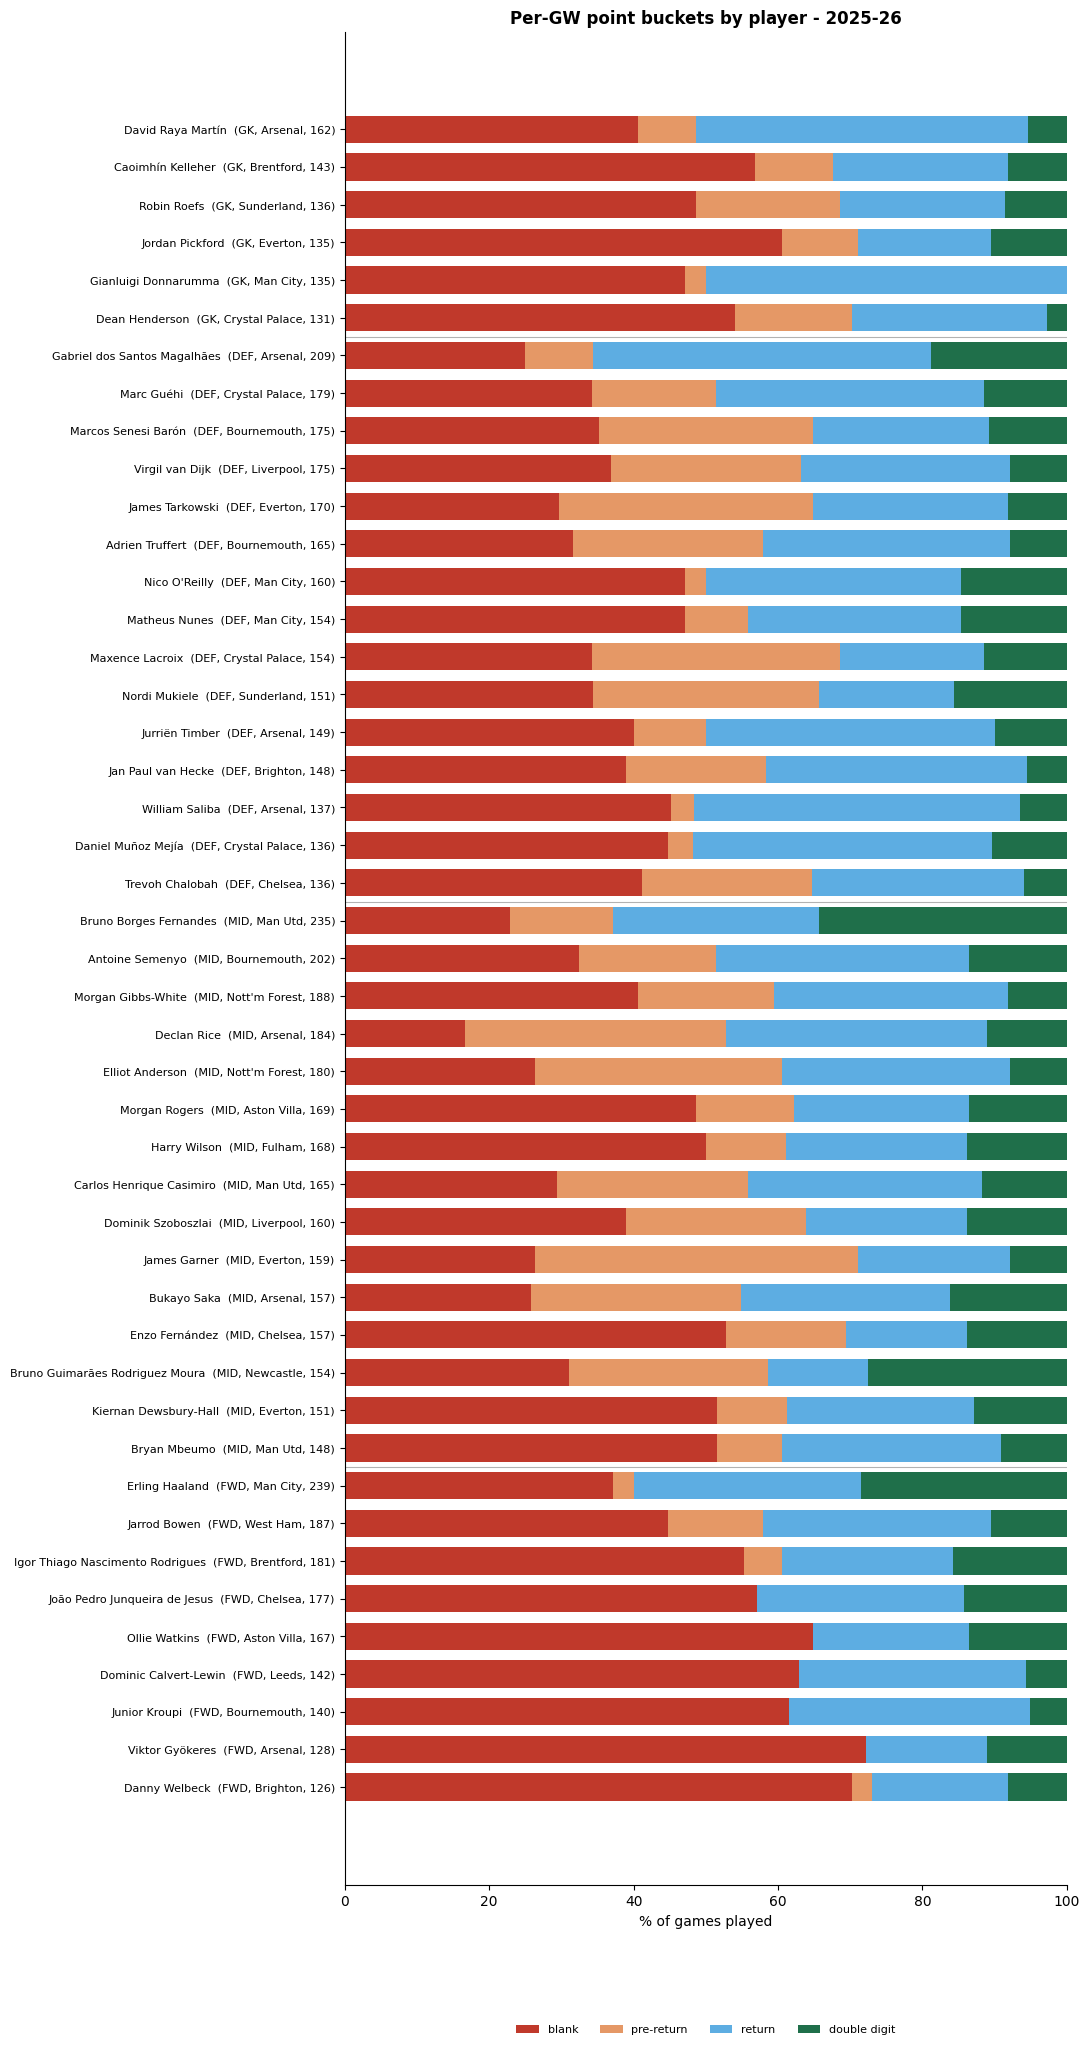

In [96]:
COLORS = {"blank": "#c0392b", "pre-return": "#e59866",
          "return": "#5dade2", "double digit": "#1f6f4a"}

d = uni.copy()
shares = d[BUCKET_NAMES].div(d["played"], axis=0) * 100
y = np.arange(len(d))

fig, ax = plt.subplots(figsize=(11, 0.42 * len(d) + 1.5))
left = np.zeros(len(d))
for b in BUCKET_NAMES:
    ax.barh(y, shares[b], left=left, color=COLORS[b], label=b, height=0.72)
    left += shares[b].values

ax.set_yticks(y)
ax.set_yticklabels([f"{n}  ({p}, {t}, {int(pt)})"
                    for n, p, t, pt in zip(d["name"], d["position"], d["team"], d["total_points"])],
                   fontsize=8)
ax.set_xlim(0, 100); ax.set_xlabel("% of games played")
ax.set_title(f"Per-GW point buckets by player - {SEASON}", fontsize=12, weight="bold")

bounds = np.cumsum([TOP_PER_POS[p] for p in ["GK", "DEF", "MID", "FWD"]])[:-1]
for b in bounds:
    ax.axhline(b - 0.5, color="black", lw=0.8, alpha=0.3)

ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.05 - 0.9/len(d)),
          fontsize=8, frameon=False)
ax.invert_yaxis(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Heatmap — the same shares as a grid

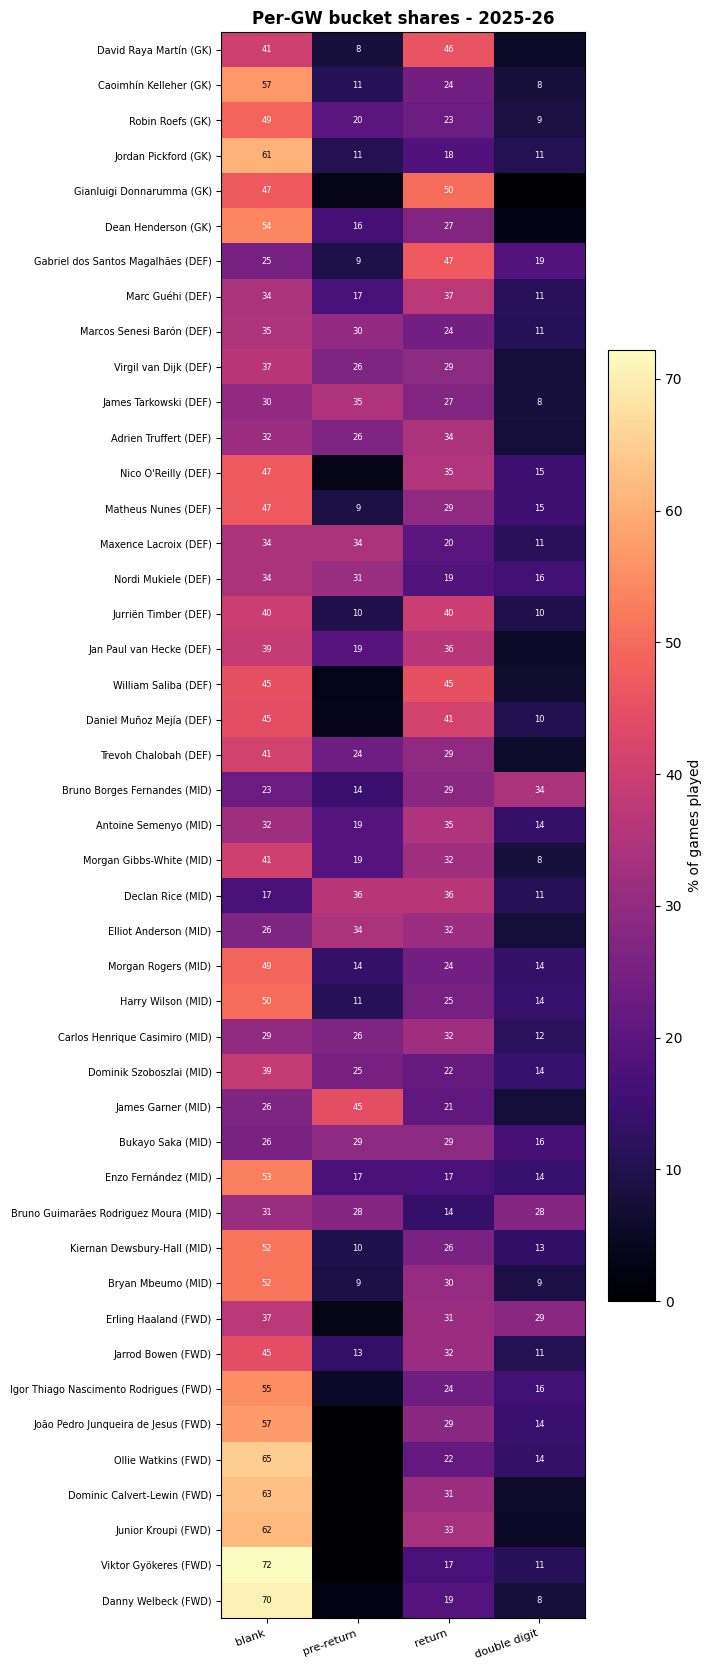

In [97]:
fig, ax = plt.subplots(figsize=(7, 0.34 * len(d) + 1.5))
M = shares[BUCKET_NAMES].values
im = ax.imshow(M, aspect="auto", cmap="magma")
ax.set_xticks(range(len(BUCKET_NAMES))); ax.set_xticklabels(BUCKET_NAMES, rotation=20, ha="right", fontsize=8)
ax.set_yticks(range(len(d)))
ax.set_yticklabels([f"{n} ({p})" for n, p in zip(d["name"], d["position"])], fontsize=7)
for i in range(len(d)):
    for j in range(len(BUCKET_NAMES)):
        if M[i, j] >= 8:
            ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center",
                    color="white" if M[i, j] < 55 else "black", fontsize=6)
fig.colorbar(im, ax=ax, label="% of games played", shrink=0.6)
ax.set_title(f"Per-GW bucket shares - {SEASON}", fontsize=12, weight="bold")
plt.tight_layout(); plt.show()

## Boom-or-bust scatter — the bridge to #07
Each player plotted by **blank share** (x) vs **double-digit share** (y), bubble = total
points. Top-right = high ceiling *and* frequent blanks (explosive/volatile); bottom-left =
low blank rate but rarely explodes (steady grinders); top-left is the dream (hauls often,
blanks rarely). The dashed line marks equal blank/DD share.

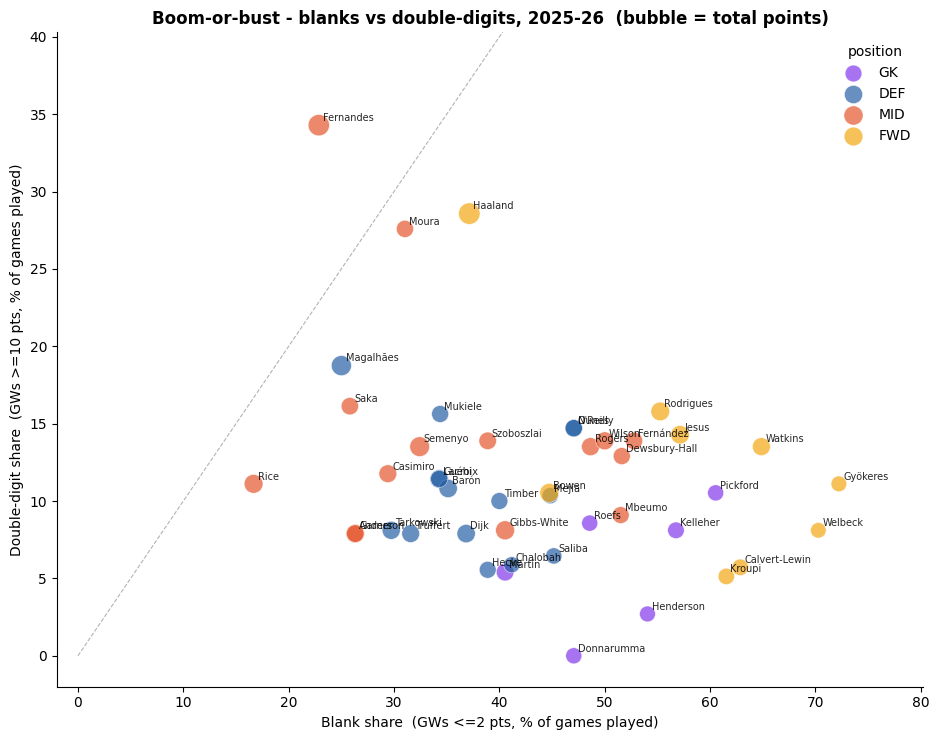

In [98]:
d["blank_share"] = shares["blank"]
d["dd_share"] = shares["double digit"]
POS_COLOR = {"GK": "#8338ec", "DEF": "#2660a4", "MID": "#e4572e", "FWD": "#f3a712"}
POS_ORDER = ["GK", "DEF", "MID", "FWD"]

fig, ax = plt.subplots(figsize=(9.5, 7.5))
for p in POS_ORDER:
    s = d[d["position"] == p]
    if len(s):
        ax.scatter(s["blank_share"], s["dd_share"], s=s["total_points"],
                   color=POS_COLOR[p], alpha=0.7, label=p, edgecolor="white", linewidth=0.5)
for _, r in d.iterrows():
    ax.annotate(r["name"].split()[-1], (r["blank_share"], r["dd_share"]),
                fontsize=7, alpha=0.85, xytext=(3, 3), textcoords="offset points")

lim = max(d["blank_share"].max(), d["dd_share"].max()) + 5
ax.plot([0, lim], [0, lim], ls="--", color="grey", lw=0.8, alpha=0.6)
ax.set_xlim(-2, d["blank_share"].max() + 8); ax.set_ylim(-2, d["dd_share"].max() + 6)
ax.set_xlabel("Blank share  (GWs <=2 pts, % of games played)")
ax.set_ylabel("Double-digit share  (GWs >=10 pts, % of games played)")
ax.set_title(f"Boom-or-bust - blanks vs double-digits, {SEASON}  (bubble = total points)",
             fontsize=12, weight="bold")
ax.legend(title="position", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()